# 1. Imports and other

Raíz

In [42]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
print(PROJECT_ROOT)

c:\Users\Carlos\Documents\Ingenieria_informatica\Proyectos_datascience\3_prediccion_precios_casas


Ruta de figures modeling

In [87]:
FIGURES_MODELING_PATH = PROJECT_ROOT / 'outputs' / 'figures_modeling'
print(FIGURES_MODELING_PATH)

c:\Users\Carlos\Documents\Ingenieria_informatica\Proyectos_datascience\3_prediccion_precios_casas\outputs\figures_modeling


Imports

In [43]:
import pandas as pd
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.neighbors import KNeighborsRegressor
import numpy as np
import matplotlib.pyplot as plt

# 2. Read data

In [44]:
df = pd.read_csv(PROJECT_ROOT / 'data' / 'processed' / 'processed_train.csv')

# 3. Split train/test

In [45]:
X = df.drop(columns=['SalePrice'])
y = df['SalePrice']

In [46]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Pipeline

Primero seleccionaremos todas nuestras columnas numéricas y categóricas

In [47]:
num_columns = df.drop(columns=['SalePrice']).select_dtypes(include=['int', 'float']).columns
num_columns

Index(['MSSubClass', 'LotFrontage', 'LotArea', 'LotShape', 'OverallQual',
       'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'ExterQual',
       'ExterCond', 'BsmtQual', 'BsmtCond', 'BsmtFinSF1', 'BsmtFinSF2',
       'BsmtUnfSF', 'TotalBsmtSF', 'HeatingQC', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Fireplaces', 'FireplaceQu', 'GarageYrBlt',
       'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'WoodDeckSF',
       'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea',
       'PoolQC', 'MiscVal', 'MoSold', 'YrSold'],
      dtype='str')

In [48]:
cat_columns = df.select_dtypes(include='str').columns
cat_columns

Index(['MSZoning', 'Street', 'Alley', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd',
       'MasVnrType', 'Foundation', 'BsmtExposure', 'BsmtFinType1',
       'BsmtFinType2', 'Heating', 'CentralAir', 'Electrical', 'Functional',
       'GarageType', 'GarageFinish', 'PavedDrive', 'Fence', 'MiscFeature',
       'SaleType', 'SaleCondition'],
      dtype='str')

## 4.1 Pipelines to impute and transform data

Este pipeline aplica la mediana de los datos aprendidos

In [49]:
pipeline_num_features = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

Este aplica la moda de los datos aprendidos y luego hace one-hot

In [50]:
pipeline_cat_features = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

El ColumnTransformer espera recibir las columnas mencionadas en num_columns/cat_columns, a eso le aplica la lógica de los pipelines anteriores

In [51]:
column_transfomer = ColumnTransformer([
    ('num_features', pipeline_num_features, num_columns),
    ('cat_features', pipeline_cat_features, cat_columns)
])

## 5. Models

Antes de seguir, crearemos un diccionario con todos los modelos que utilizaremos

In [52]:
models_dict = {
    'LinearRegression': LinearRegression(),
    'RandomForestRegressor': RandomForestRegressor(),
    'KNeighborsRegressor': KNeighborsRegressor(),
    'XGBRegressor': XGBRegressor()
}

## 6. KFold

Utilizaremos KFold para poder evaluar los modelos con distintas distribuciones de los datos

In [53]:
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

# 7. Evaluate models in train

Metricas que queremos evaluar (puede ser una lista, pero colocarlas en un diccionario hace que luego en los resultados, se pueda buscar con el nombre de la llave, lo cual lo hace más sencillo)

In [54]:
METRICS = {
    'mae': 'neg_mean_absolute_error',
    'rmse': 'neg_root_mean_squared_error',
    'r2': 'r2'
}

Primero veremos como se comportan los modelos para los datos de entrenamiento

In [55]:
metrics_train_df = pd.DataFrame()

In [56]:
for model in models_dict:
    # Crear pipeline con el modelo actual
    pipeline = Pipeline([
        ('preprocess', column_transfomer),
        ('scaler', StandardScaler()),
        ('model', models_dict[model])
    ])

    # Hacer las 5 particiones y evaluar métricas en cada una
    results = cross_validate(
        estimator=pipeline,
        X=X_train,
        y=y_train,
        cv=kfold,
        scoring=METRICS
    )

    # Obtener promedios y distribuciones estándar de los resultados
    maes = -results['test_mae']
    mean_mae = np.mean(maes)
    std_mae = np.std(maes)

    rmses = -results['test_rmse']
    mean_rmse = np.mean(rmses)
    std_rmse = np.std(rmses)

    r2 = results['test_r2']
    mean_r2 = np.mean(r2)
    std_r2 = np.std(r2)

    # DataFrame para luego visualizar resultados
    metrics_train_df_to_add = pd.DataFrame({
        'Model': [model],
        'Mean_mae': [mean_mae],
        'Std_mae': [std_mae],
        'Mean_rmse': [mean_rmse],
        'Std_rmse': [std_rmse],
        'Mean_r2': [mean_r2],
        'Std_r2': [std_r2]
    })

    
    metrics_train_df = pd.concat([metrics_train_df, metrics_train_df_to_add])

In [57]:
metrics_train_df

,Model,Mean_mae,Std_mae,Mean_rmse,Std_rmse,Mean_r2,Std_r2
0,LinearRegression,20388.386088,1405.345915,36132.735386,7825.086464,0.773231,0.085464
0,RandomForestRegressor,18125.263069,976.608446,30501.302889,4759.345284,0.841476,0.042499
0,KNeighborsRegressor,26258.626755,2330.162480,42481.471631,4742.962682,0.696382,0.042826
0,XGBRegressor,18686.272656,1786.304906,31877.489453,6380.830841,0.825601,0.059595


# 8. Visualize results of train

Definir colores del proyecto

In [84]:
PROJECT_COLORS = ["#2DD61D", "#3410FF"]

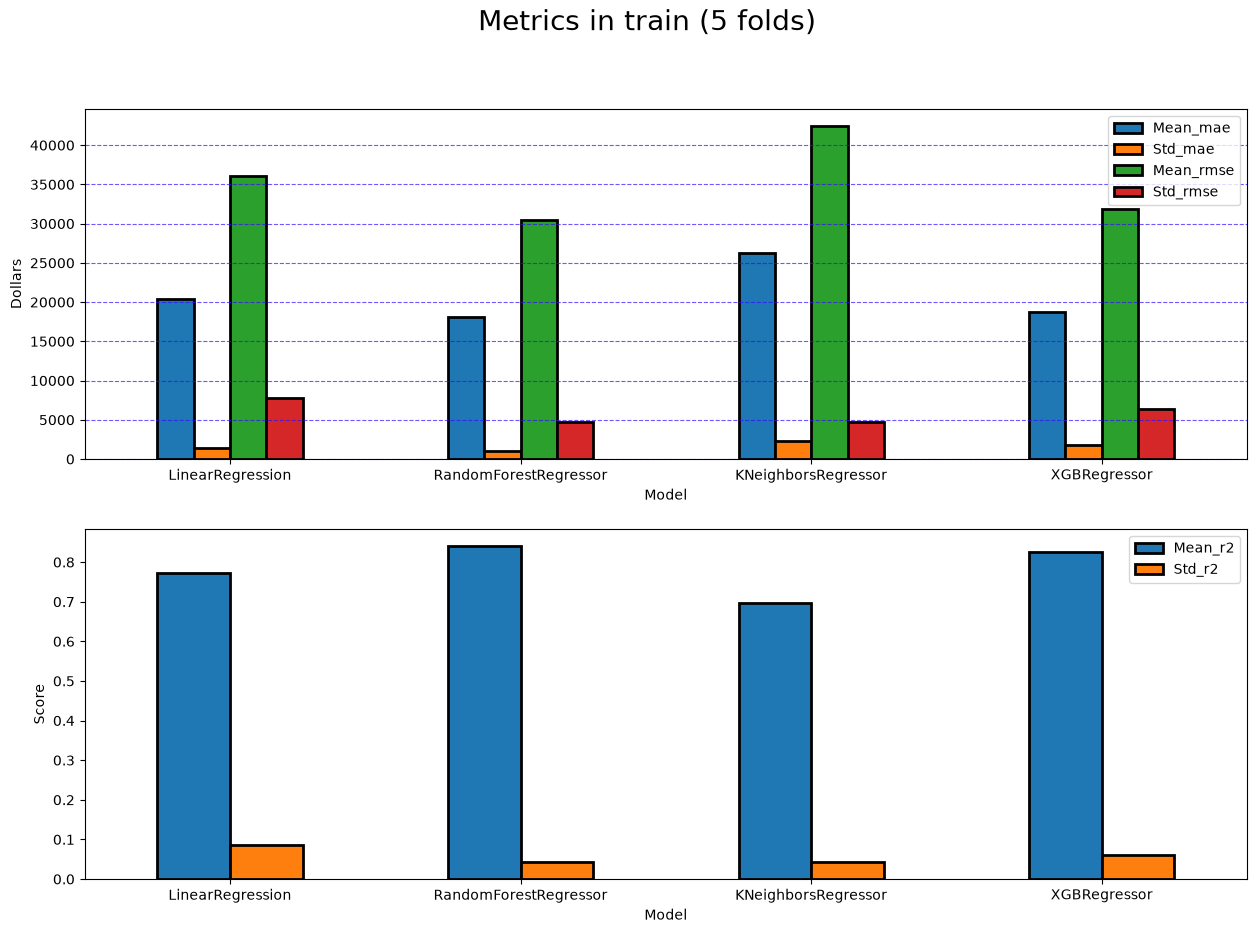

In [88]:
fig, ax = plt.subplots(2, 1, figsize=(15, 10))

metrics_train_df.plot(
    kind='bar',
    x='Model',
    y=['Mean_mae', 'Std_mae', 'Mean_rmse', 'Std_rmse'],
    rot=0,
    edgecolor='black',
    linewidth=2,
    ax=ax[0]
)
ax[0].set_ylabel('Dollars')
ax[0].grid(color=PROJECT_COLORS[1], axis='y', linestyle='--', alpha=0.7)


metrics_train_df.plot(
    kind='bar',
    x='Model',
    y=['Mean_r2', 'Std_r2'],
    rot=0,
    edgecolor='black',
    linewidth=2,
    ax=ax[1]
)
ax[1].set_ylabel('Score')


fig.suptitle(
    'Metrics in train (5 folds)',
    fontsize=20
)


plt.savefig(FIGURES_MODELING_PATH / '01_metrics_in_train_with_5_folds.png', bbox_inches='tight')
plt.show()